In [1]:
import adabmDCA as dca
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import RNA

from concurrent.futures import ProcessPoolExecutor
from functools import partial

# use latex and font size 14
plt.rc('text', usetex=True)
plt.rc('font', size=14)

tokens = "ACGU-"
dot_bracket_with_pk = "...(((((((..((....)).)))))))...((((((....((((((...((...((((((....))))))..))...))))))(((...(.((((((....)))))).)..)))...[.[[[[[...))))))((((...(((....)))..))))......]]]]]]..((.(((((....))))).....)).."

In [39]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

In [40]:
def compute_bpp_matrix(sequence):
    """
    Compute the base-pairing probability (bpp) matrix via ViennaRNA.

    Parameters
    ----------
    sequence : str
        RNA sequence (T già convertiti in U se presenti gap).

    Returns
    -------
    bpp : np.ndarray, shape (L, L)
        Matrice simmetrica delle probabilità di appaiamento (L = len(sequence)).
    """
    fc = RNA.fold_compound(sequence)
    propensity, ensemble_energy = fc.pf()
    basepair_probs = fc.bpp()  # nested list, 1-based

    L = len(sequence)
    bpp = np.zeros((L, L), dtype=float)
    for i in range(1, L+1):
        for j in range(1, L+1):
            bpp[i-1, j-1] = basepair_probs[i][j]
    return bpp


def dot_bracket_to_ss_matrix(ss):
    """
    Convert a dot-bracket string into a binary contact matrix.

    Parameters
    ----------
    ss : str
        Notazione secondaria “dot-bracket”.

    Returns
    -------
    cm : np.ndarray, shape (L, L)
        Matrice binaria con cm[i,j]=1 se i e j sono appaiati nella struttura.
    """
    L = len(ss)
    cm = np.zeros((L, L), dtype=int)
    stack_round = []  # for (
    stack_square = []  # for [
    stack_angle = []  # for <
    stack_curly = []  # for {
    for pos, c in enumerate(ss):
        if c == '(':
            stack_round.append(pos)
        elif c == '[':
            stack_square.append(pos)
        elif c == '<':
            stack_angle.append(pos)
        elif c == '{':
            stack_curly.append(pos)
        elif c == ')':
            if stack_round:
                i = stack_round.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == ']':
            if stack_square:
                i = stack_square.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '>':
            if stack_angle:
                i = stack_angle.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '}':
            if stack_curly:
                i = stack_curly.pop()
                cm[i, pos] = cm[pos, i] = 1
    return cm



def _bpp_score_for_sequence(seq, cm):
    seq = seq.upper().replace('T', 'U')
    bpp = compute_bpp_matrix(seq)
    return float((bpp * cm).sum())

def compute_bpp_scores(sequences_one_hot, dot_bracket, num_workers=4):
    sequences_v = torch.argmax(sequences_one_hot, dim=-1)
    sequences = ["GUG"+ "".join(tokens[i] for i in sequence) + "G" for sequence in sequences_v]

    """
    Compute BPP scores and gap violations for a list of sequences given a dot-bracket structure.

    Args:
        sequences (list of str): List of RNA sequences (strings with 'U' instead of 'T').
        dot_bracket (str): Dot-bracket string representing the structure.
        num_workers (int): Number of processes to parallelize over.

    Returns:
        bpp_scores (list of float): BPP scores for each sequence.
        gap_violations (int): Number of gap violations across all sequences.
    """
    # Convert dot-bracket to structure matrix once
    cm = dot_bracket_to_ss_matrix(dot_bracket)

    # Use process pool to parallelize computation
    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        bpp_scores = list(executor.map(partial(_bpp_score_for_sequence, cm=cm), sequences))

    return bpp_scores

In [71]:
path_model_franc = "/home/lorenzo/Documents/paths-specificity/Group_I_Intron/modello_FC_T=1"
path_model_lore = "/home/lorenzo/Documents/paths-specificity/lore/per_giova/models/reint/eaDCA-lambda_500.0_params.dat"

params_np = np.load(path_model_franc)
params_franc = {
    'bias': torch.tensor(params_np['h_local'], dtype=torch.float32, device='cuda').contiguous(),
    'coupling_matrix': torch.tensor(params_np['couplings'], dtype=torch.float32, device='cuda').contiguous()
}

params_lore = dca.load_params(path_model_lore, tokens=tokens, device=device, dtype=dtype)
# Set the bias of the gaps to a very large negative value to avoid gaps in the sequences
gap_idz = tokens.index('-')
params_lore['bias'][:, gap_idz] = -1e6

In [72]:
num_chains = 1000
nsweeps = 1000

L, q = params_franc['bias'].shape
init_chains = dca.utils.init_chains(
    num_chains=num_chains,
    L=L,
    q=q,
    device=device,
    dtype=dtype,
)

In [73]:
samples_franc = dca.gibbs_sampling(
    chains=init_chains,
    params=params_franc,
    nsweeps=nsweeps,
)

In [74]:
samples_lore = dca.gibbs_sampling(
    chains=init_chains,
    params=params_lore,
    nsweeps=nsweeps,
)

In [75]:
bpp_scores_franc = compute_bpp_scores(samples_franc, dot_bracket_with_pk, num_workers=20)
bpp_scores_lore = compute_bpp_scores(samples_lore, dot_bracket_with_pk, num_workers=20)

In [76]:
energies_franc_by_lore = dca.compute_energy(samples_lore, params_franc)
energies_lore_by_franc = dca.compute_energy(samples_franc, params_lore)
energies_franc_by_franc = dca.compute_energy(samples_franc, params_franc)
energies_lore_by_lore = dca.compute_energy(samples_lore, params_lore)

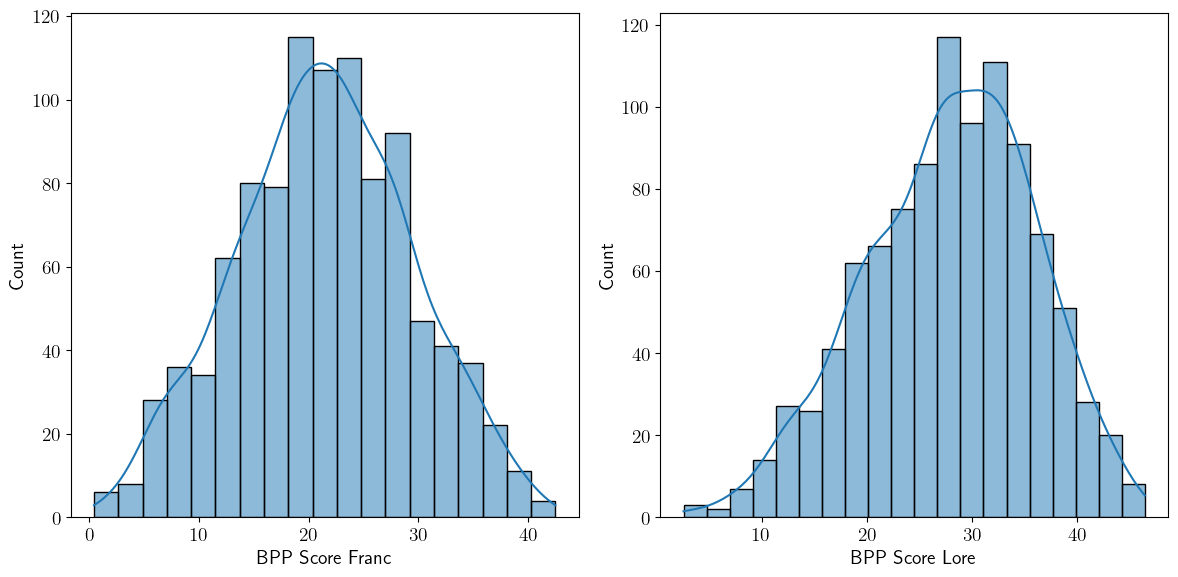

In [77]:
df_results = pd.DataFrame({
    'BPP Score Franc': bpp_scores_franc,
    'BPP Score Lore': bpp_scores_lore,
    'Energy Franc by Lore': energies_franc_by_lore.cpu().numpy(),
    'Energy Lore by Franc': energies_lore_by_franc.cpu().numpy(),
    'Energy Franc by Franc': energies_franc_by_franc.cpu().numpy(),
    'Energy Lore by Lore': energies_lore_by_lore.cpu().numpy()
})

fig, ax = plt.subplots(1, 2, figsize=(12,6))
sns.histplot(
    data=df_results,
    x='BPP Score Franc',
    ax=ax[0],
    kde=True
)
sns.histplot(
    data=df_results,
    x='BPP Score Lore',
    ax=ax[1],
    kde=True
)

plt.tight_layout()

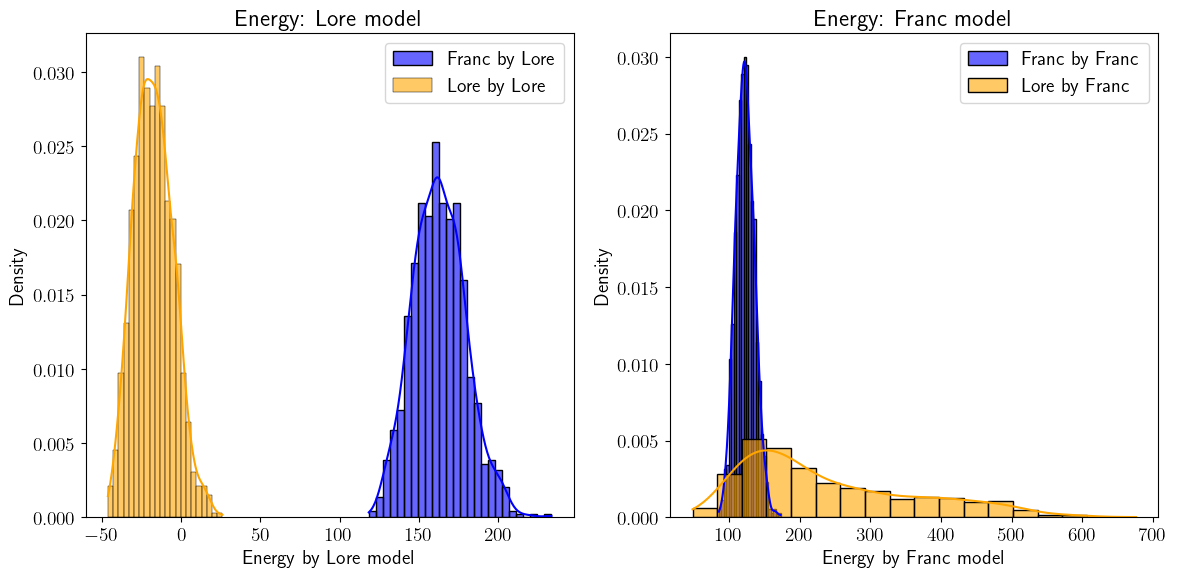

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(12,6))

# Histogram of energies Franc by Lore vs Lore by Lore
sns.histplot(
    data=df_results,
    x='Energy Franc by Lore',
    ax=ax[0],
    color='blue',
    label='Franc by Lore',
    kde=True,
    stat='density',
    alpha=0.6
)
sns.histplot(
    data=df_results,
    x='Energy Lore by Lore',
    ax=ax[0],
    color='orange',
    label='Lore by Lore',
    kde=True,
    stat='density',
    alpha=0.6
)
ax[0].legend()
ax[0].set_xlabel('Energy by Lore model')
ax[0].set_title('Energy: Lore model')

sns.histplot(
    data=df_results,
    x='Energy Franc by Franc',
    ax=ax[1],
    color='blue',
    label='Franc by Franc',
    kde=True,
    stat='density',
    alpha=0.6
)

# Histogram of energies Lore by Franc vs Franc by Franc
sns.histplot(
    data=df_results,
    x='Energy Lore by Franc',
    ax=ax[1],
    color='orange',
    label='Lore by Franc',
    kde=True,
    stat='density',
    alpha=0.6
)

ax[1].legend()
ax[1].set_title('Energy: Franc model')
ax[1].set_xlabel('Energy by Franc model')
plt.tight_layout()